In [1]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt


# Loading the data and doing regular stuff

In [2]:
df= pd.read_excel("/kaggle/input/datasets/daminijadhav2003/crop-predication-dataset-based-on-nashik-region/Crop_Predication_dataset.xlsx")
df.head()

,ph,EC,CaCO3,OC,N,P,K,label
0,5.6,0.330,6.0,0.16,125.0,37.0,200.0,bajra
1,7.5,0.820,7.0,0.15,132.0,35.0,169.0,bajra
2,5.6,0.212,3.0,0.19,145.0,38.0,122.0,bajra
3,6.9,0.469,9.0,0.14,124.0,38.0,134.0,bajra
4,7.3,0.649,6.0,0.18,125.0,35.0,162.0,bajra


In [3]:
df.shape

(1239, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1239 entries, 0 to 1238
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ph      1239 non-null   float64
 1   EC      1239 non-null   float64
 2   CaCO3   1239 non-null   float64
 3   OC      1239 non-null   float64
 4   N       1239 non-null   float64
 5   P       1239 non-null   float64
 6   K       1239 non-null   float64
 7   label   1239 non-null   object 
dtypes: float64(7), object(1)
memory usage: 77.6+ KB


In [5]:
df.describe()

,ph,EC,CaCO3,OC,N,P,K
count,1239.000000,1239.000000,1239.000000,1239.000000,1239.000000,1239.000000,1239.000000
mean,8.598764,0.435471,5.873971,1.657602,141.332155,27.511345,203.485446
std,33.566082,0.250498,3.683088,2.003687,67.349392,21.106725,149.758253
min,5.000000,0.007000,0.000000,0.001900,0.000000,1.030000,35.000000
25%,6.126350,0.250000,3.600000,0.195000,83.000000,12.000000,71.000000
50%,6.600000,0.341000,4.700000,0.520000,151.000000,18.000000,170.000000
75%,7.118269,0.610000,7.000000,3.200000,184.730000,39.000000,304.050000
max,598.000000,1.640000,18.000000,8.500000,342.340000,85.000000,1170.350000


In [6]:
df.isnull().sum()

ph       0
EC       0
CaCO3    0
OC       0
N        0
P        0
K        0
label    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(80)

In [8]:
# 1. Duplicate rows ko remove karna
df = df.drop_duplicates()
print("Duplicates remove karne ke baad shape:", df.shape)

# 2. Impossible pH values ko filter karna (Sirf 0 se 14 wali values rakhna)
df = df[(df['ph'] >= 0) & (df['ph'] <= 14)]
print("Outliers remove karne ke baad shape:", df.shape)

# 3. Target variable (label) ki distribution check karna
# Yeh dekhna zaroori hai ke kya har crop ka data barabar hai ya imbalanced hai
print("\nCrop (Label) Value Counts:")
print(df['label'].value_counts())

Duplicates remove karne ke baad shape: (1159, 8)
Outliers remove karne ke baad shape: (1158, 8)

Crop (Label) Value Counts:
label
grapes         116
cabbage        101
bajra          101
maize          101
jowar          101
sugarcane      101
wheat          101
pomegranate    100
cotton          84
soybean         82
tomato          55
rice            51
onion           34
potato          24
cauliflower      6
Name: count, dtype: int64


# Univariate Analysis

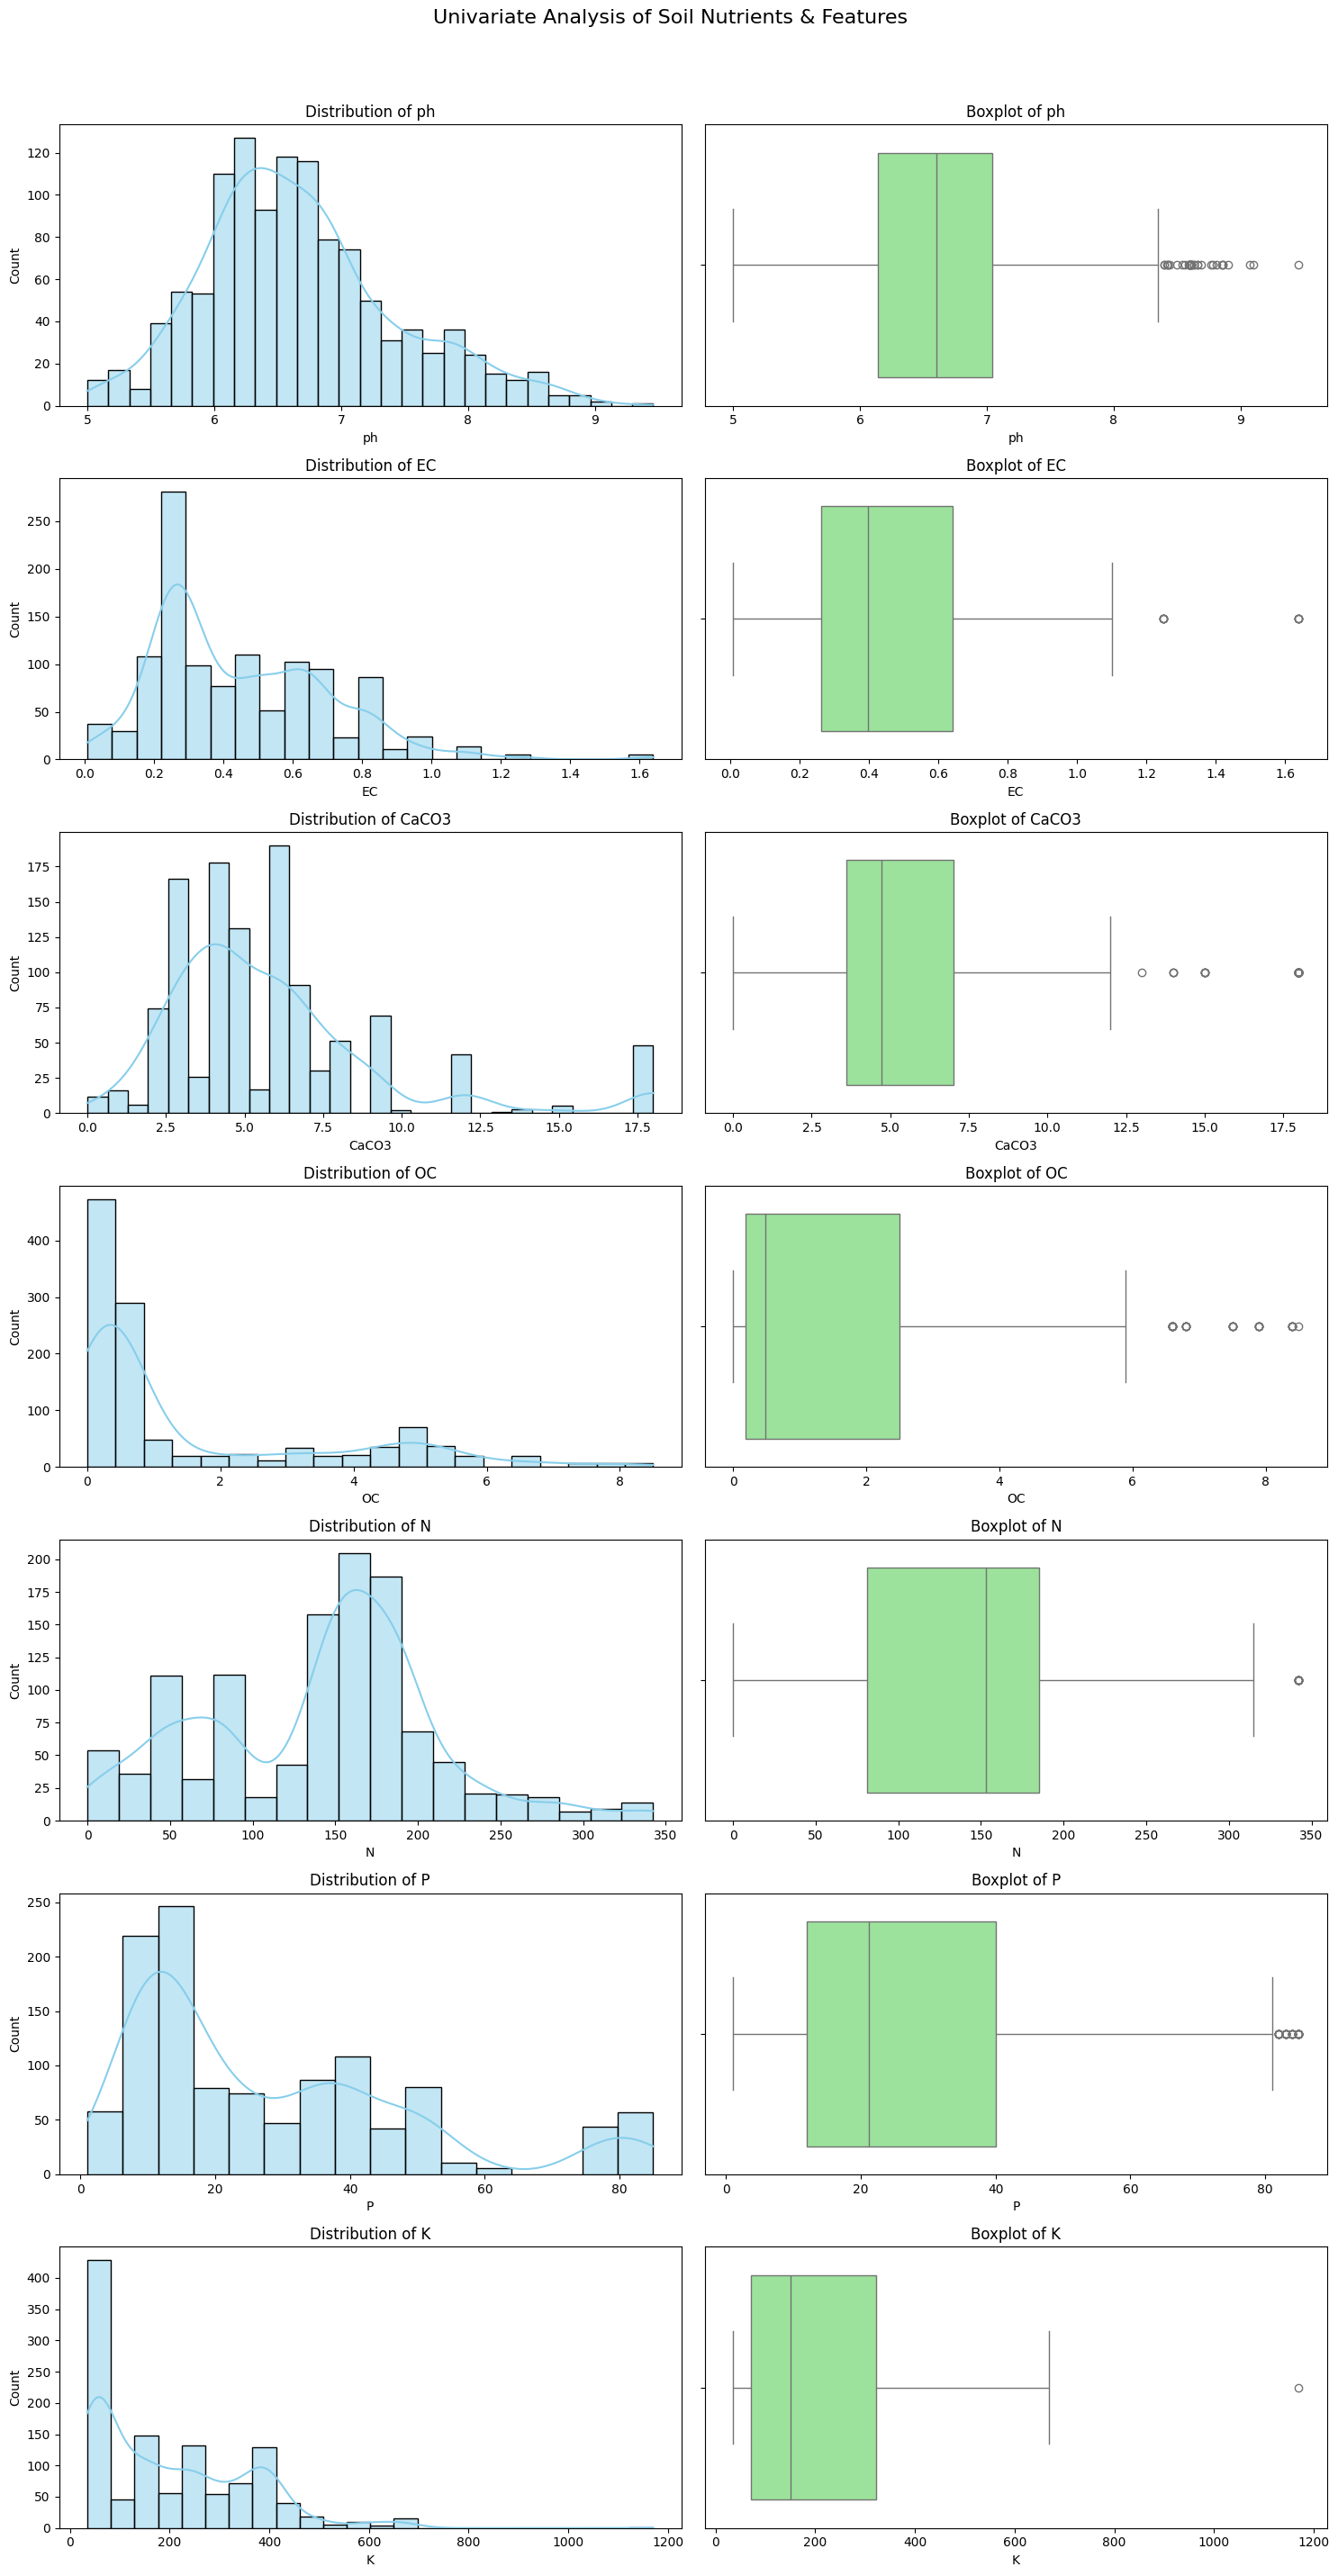

In [9]:
# Numerical columns ko extract karna
num_cols = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(nrows=len(num_cols), ncols=2, figsize=(15, 4 * len(num_cols)))
fig.suptitle('Univariate Analysis of Soil Nutrients & Features', fontsize=16, y=1.02)

for i, col in enumerate(num_cols):
    # Histogram (Data Skewness check karne ke liye)
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Distribution of {col}')
    
    # Boxplot (Outliers check karne ke liye)
    sns.boxplot(x=df[col], ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

**Univariate analysis ne soil features ki individual distributions aur unke anomalies ko wazeh kiya. Boxplots aur histograms se pata chala ke numerical columns jaise 'ph', 'P', aur 'K' mein extreme outliers mojood hain (maslan pH ki maximum value 598.0 jo scientifically impossible hai). Iske ilawa, 'K' (Potassium) aur 'P' (Phosphorus) ki standard deviation kafi high hai, jo mitti ki quality mein heavy variance ko zahir karti hai. Is insight ne humein technically yeh bataya ke model training se pehle in outliers ko properly filter karna aur distance-based algorithms ke liye data ko StandardScaler ke zariye normalize karna intehai zaroori hai taake model ke weights distort na hon.**

# Bivariate Analysis

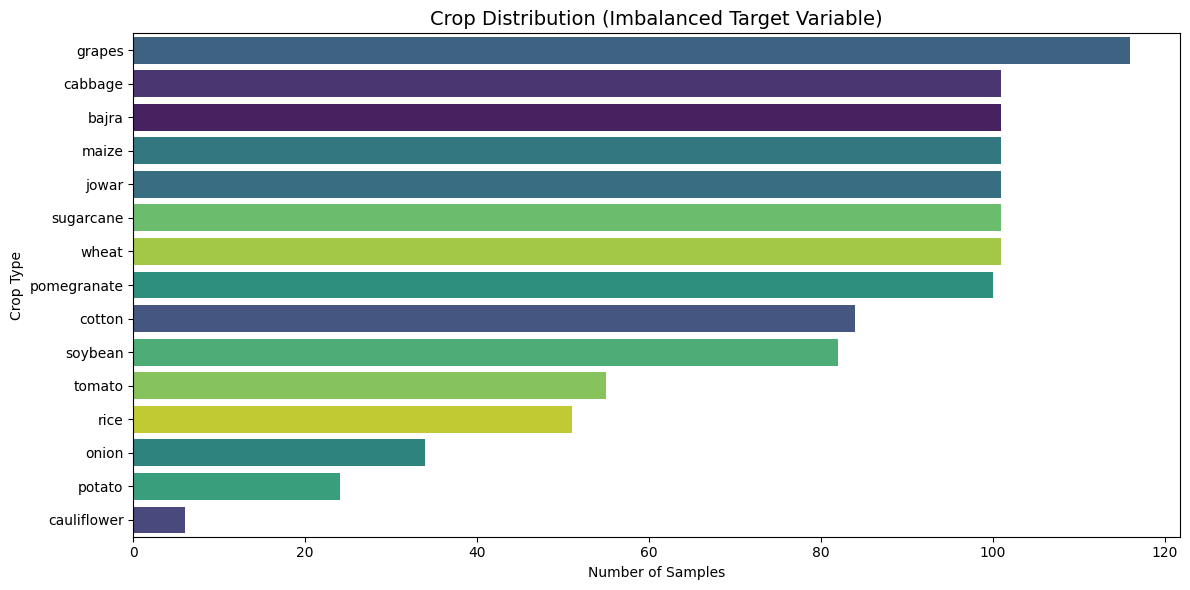

In [10]:
# Target Distribution

plt.figure(figsize=(12, 6))

# Warning-free code: hue assign kiya aur legend=False rakha
sns.countplot(data=df, y='label', hue='label', 
              order=df['label'].value_counts().index, 
              palette='viridis', legend=False)

plt.title('Crop Distribution (Imbalanced Target Variable)', fontsize=14)
plt.xlabel('Number of Samples')
plt.ylabel('Crop Type')
plt.tight_layout()
plt.show()

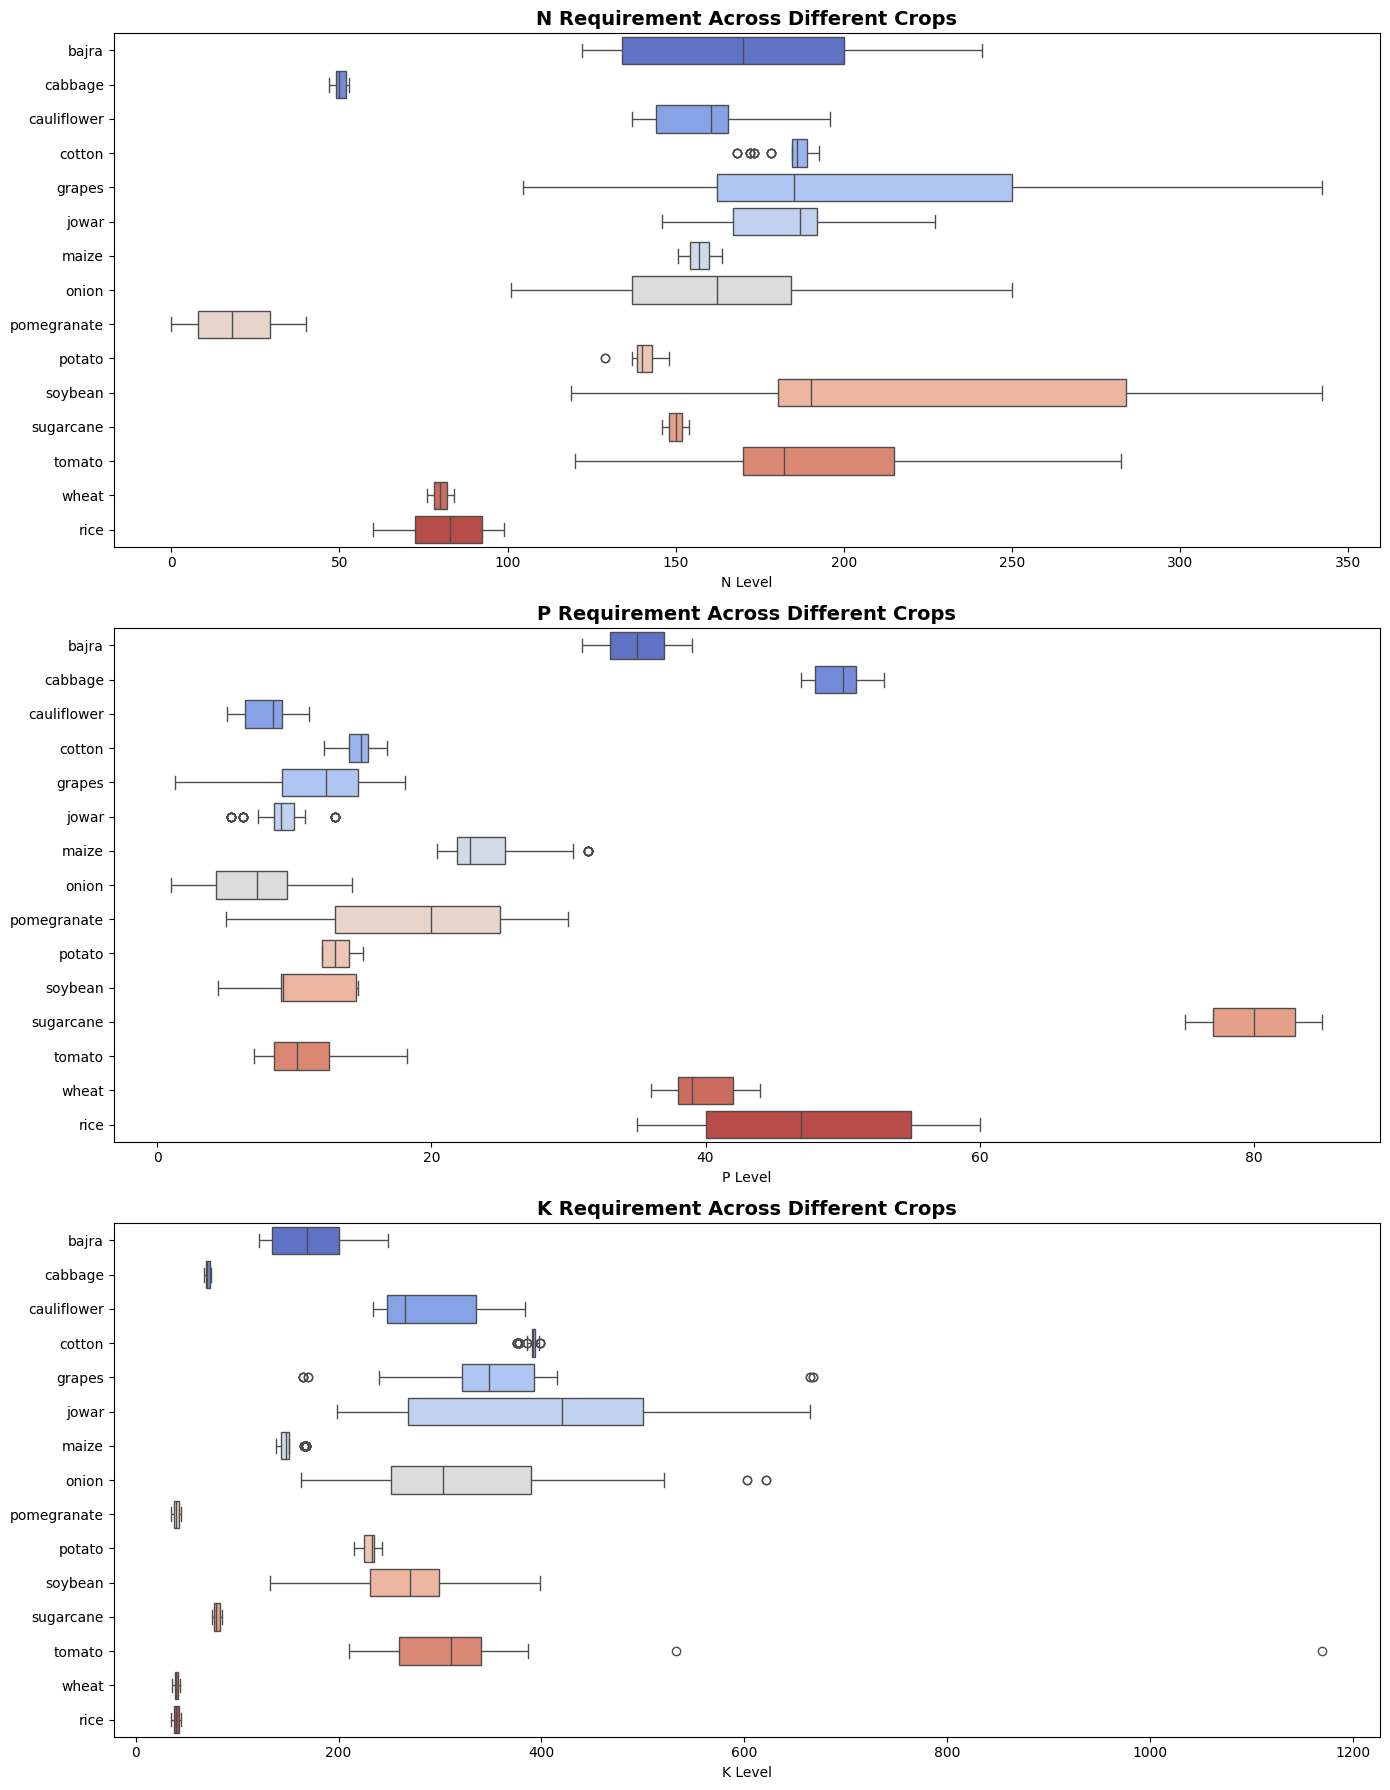

In [11]:
# Macro Nutrients (N, P, K)

macro_nutrients = ['N', 'P', 'K']

# Figsize lamba rakha hai taake 15 crops clearly fit ho sakein
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 18))

for i, col in enumerate(macro_nutrients):
    # y='label' kiya hai taake crop names vertical axis par aayen aur parhne mein asani ho
    sns.boxplot(data=df, x=col, y='label', hue='label', 
                palette='coolwarm', legend=False, ax=axes[i])
    
    axes[i].set_title(f'{col} Requirement Across Different Crops', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('') # Y-axis ka title hide kar diya taake clutter kam ho
    axes[i].set_xlabel(f'{col} Level')

plt.tight_layout()
plt.show()

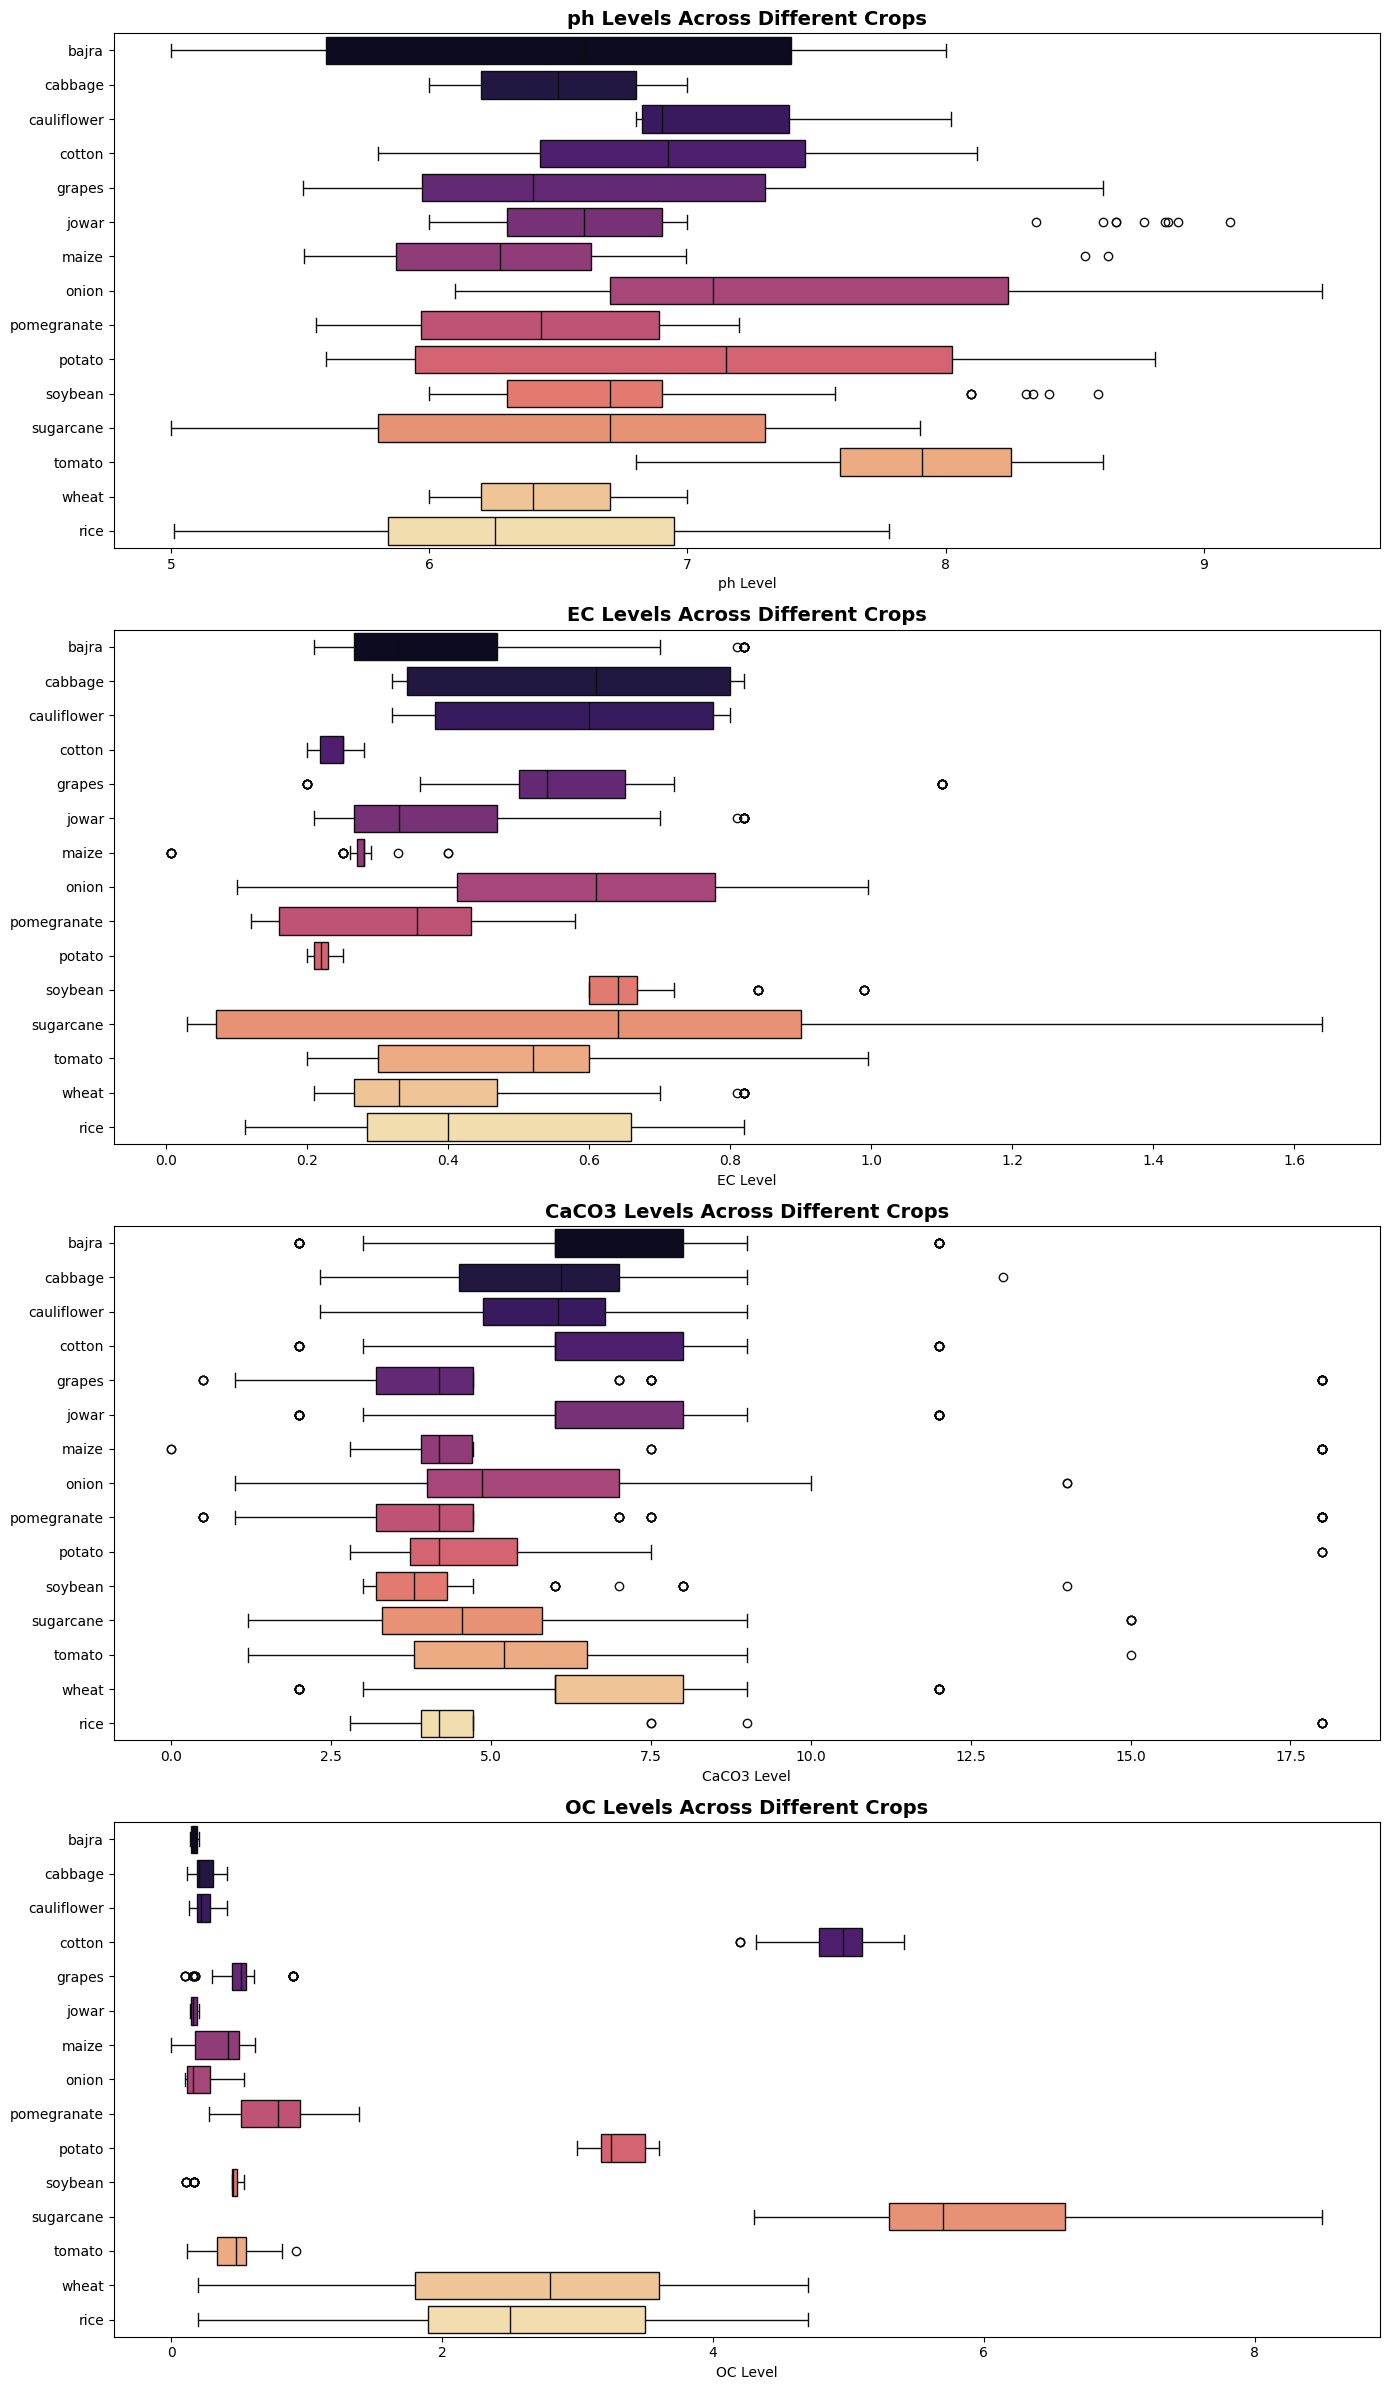

In [12]:
#Soil Properties

soil_props = ['ph', 'EC', 'CaCO3', 'OC']

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 24))

for i, col in enumerate(soil_props):
    sns.boxplot(data=df, x=col, y='label', hue='label', 
                palette='magma', legend=False, ax=axes[i])
    
    axes[i].set_title(f'{col} Levels Across Different Crops', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('') 
    axes[i].set_xlabel(f'{col} Level')

plt.tight_layout()
plt.show()

**Bivariate analysis (boxplots) ke zariye humne independent soil features (Macro Nutrients aur Physical Properties) ka target variable (Crop/label) ke sath direct relationship analyze kiya. Har crop ki nutrient requirement doosri se bilkul mukhtalif aur wazeh (distinct) nazar aayi. Zyadatar crops ke boxplots specific nutrients ke liye completely alag heights par the, jo zahir karta hai ke data mein classes aapas mein heavily overlap nahi kar rahin. Yeh clear "class separability" is baat ka strong statistical saboot hai ke hamare features mein high predictive power hai, jo aage chal kar Random Forest ya XGBoost jaise tree-based models ko mathematically accurate splits banane mein madad degi.**

# Multivariate Analysis

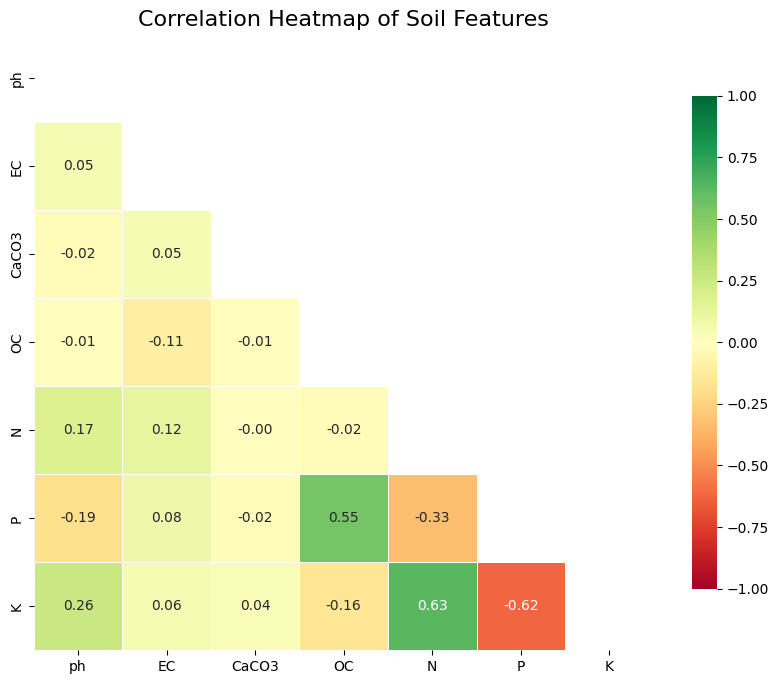

In [13]:
plt.figure(figsize=(10, 8))
corr_matrix = df[num_cols].corr()

# Upper triangle ko hide karna taake map clean lage
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='RdYlGn', 
            vmin=-1, vmax=1, center=0, fmt=".2f", linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Correlation Heatmap of Soil Features', fontsize=16)
plt.show()

**Multivariate analysis mein correlation heatmap ne is dataset ki biological validity ko practically prove kar diya, kyunke isme features ke darmiyan natural chemical dependencies mojood hain. Heatmap se wazeh hua ke 'K' aur 'N' mein strong positive correlation (0.63) hai, jabke 'K' aur 'P' mein strong negative correlation (-0.62) observe ki gayi. Sab se ahem technical insight yeh mili ke dataset mein koi bhi do independent variables aapas mein highly correlated (e.g., > 0.85) nahi hain. Iska matlab hai ke data mein "Multicollinearity" ka masla mojood nahi, isliye humein Dimensionality Reduction (PCA) apply karne ya kisi makhsoos column ko drop karne ki zaroorat nahi hai.**

# Creating pipelines and using SMOTE

In [14]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 1. Target aur Features ko alag karna
X = df.drop('label', axis=1)
y = df['label']

# 2. Target Variable Encoding (Pipelines features pe lagti hain, target pe nahi)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 3. Train-Test Split (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 4. SMOTE -> Scaler -> Model
# k_neighbors=3 rakha hai taake minority class (cauliflower) par error na aaye
# Random Forest Pipeline
rf_pipeline = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42, k_neighbors=3)),
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# XGBoost Pipeline
xgb_pipeline = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42, k_neighbors=3)),
    ('scaler', StandardScaler()),
    ('classifier', XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss'))
])

# 5. Pipelines ko Train (Fit) Karna
print("Training Random Forest Pipeline...")
rf_pipeline.fit(X_train, y_train)

print("Training XGBoost Pipeline...")
xgb_pipeline.fit(X_train, y_train)

# 6. Predictions
rf_preds = rf_pipeline.predict(X_test)
xgb_preds = xgb_pipeline.predict(X_test)

# 7. Evaluation
print("\n" + "="*55)
print(f"Random Forest Overall Accuracy: {accuracy_score(y_test, rf_preds) * 100:.2f}%")
print(f"XGBoost Overall Accuracy:       {accuracy_score(y_test, xgb_preds) * 100:.2f}%")
print("="*55 + "\n")

print("Detailed Classification Report (Random Forest):")
print("-" * 55)
print(classification_report(y_test, rf_preds, target_names=le.classes_))

print("\n" + "="*55 + "\n")

print("Detailed Classification Report (XGBoost):")
print("-" * 55)
print(classification_report(y_test, xgb_preds, target_names=le.classes_))

Training Random Forest Pipeline...
Training XGBoost Pipeline...

Random Forest Overall Accuracy: 93.97%
XGBoost Overall Accuracy:       94.40%

Detailed Classification Report (Random Forest):
-------------------------------------------------------
              precision    recall  f1-score   support

       bajra       1.00      1.00      1.00        20
     cabbage       1.00      1.00      1.00        20
 cauliflower       0.00      0.00      0.00         1
      cotton       1.00      1.00      1.00        17
      grapes       0.91      0.88      0.89        24
       jowar       0.95      1.00      0.98        20
       maize       1.00      1.00      1.00        20
       onion       0.67      0.57      0.62         7
 pomegranate       1.00      1.00      1.00        20
      potato       1.00      1.00      1.00         5
        rice       1.00      0.80      0.89        10
     soybean       0.80      0.94      0.86        17
   sugarcane       1.00      1.00      1.00      

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/m

**Train-Test split mein Cauliflower ke test set mein sirf 1 sample hone ki wajah se F1-score 0 aaraha tha (Due to extreme low support). Is anomaly ko handle karne aur model ki robust performance verify karne ke liye humne 5-Fold Stratified Cross-Validation implement ki.**

# Stratified K-fold cross

In [15]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

# 5-Fold Stratified CV
# Chunke cauliflower ke total 6 samples hain, n_splits=5 ensure karega 
# ke har fold ke test set mein kam az kam 1 cauliflower zaroor aaye.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Running 5-Fold Cross-Validation for Random Forest...")
# scoring='f1_macro' isliye use kiya taake minority classes (cauliflower, potato) ko barabar weight mile
rf_cv_scores = cross_val_score(rf_pipeline, X, y_encoded, cv=skf, scoring='f1_macro')

print("Running 5-Fold Cross-Validation for XGBoost...")
xgb_cv_scores = cross_val_score(xgb_pipeline, X, y_encoded, cv=skf, scoring='f1_macro')

print("\n" + "="*55)
print(f"Random Forest CV Macro F1-Score: {rf_cv_scores.mean() * 100:.2f}% (+/- {rf_cv_scores.std() * 100:.2f}%)")
print(f"XGBoost CV Macro F1-Score:       {xgb_cv_scores.mean() * 100:.2f}% (+/- {xgb_cv_scores.std() * 100:.2f}%)")
print("="*55 + "\n")

Running 5-Fold Cross-Validation for Random Forest...
Running 5-Fold Cross-Validation for XGBoost...

Random Forest CV Macro F1-Score: 88.20% (+/- 3.21%)
XGBoost CV Macro F1-Score:       88.21% (+/- 2.03%)



In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

# cross_val_predict har sample ki prediction tab karta hai jab wo test fold mein hota hai
print("Generating Cross-Validated Predictions for XGBoost (Winning Model)...")
xgb_cv_preds = cross_val_predict(xgb_pipeline, X, y_encoded, cv=skf)

print("\n" + "="*55)
print("Detailed CV Classification Report (XGBoost):")
print("-" * 55)
# Yahan true labels (y_encoded) ko CV predictions (xgb_cv_preds) ke sath compare kar rahe hain
print(classification_report(y_encoded, xgb_cv_preds, target_names=le.classes_))

Generating Cross-Validated Predictions for XGBoost (Winning Model)...

Detailed CV Classification Report (XGBoost):
-------------------------------------------------------
              precision    recall  f1-score   support

       bajra       1.00      1.00      1.00       101
     cabbage       1.00      1.00      1.00       101
 cauliflower       0.00      0.00      0.00         6
      cotton       1.00      1.00      1.00        84
      grapes       0.93      0.90      0.91       116
       jowar       0.97      1.00      0.99       101
       maize       1.00      1.00      1.00       101
       onion       0.72      0.68      0.70        34
 pomegranate       1.00      1.00      1.00       100
      potato       0.96      1.00      0.98        24
        rice       0.98      0.92      0.95        51
     soybean       0.92      0.95      0.93        82
   sugarcane       1.00      1.00      1.00       101
      tomato       0.81      0.80      0.81        55
       wheat     

# Limitation of this project

**During Cross-Validation, Cauliflower achieved a 0% F1-Score despite SMOTE. Upon deep analysis, it was observed that Cauliflower has extremely low support (only 6 samples) and its biochemical features completely overlap with Cabbage (101 samples). Due to this lack of separability and extreme minority status, the model statistically classifies it as Cabbage. The professional recommendation for future work is either to collect more data for Cauliflower or drop this class to prevent noise.**

# Saving the model

In [17]:
import joblib

# Humne pehle xgb_pipeline ko poore data (X, y_encoded) par train nahi kiya tha,
# cross-validation sirf test kar rahi thi. Ab hum final model ko poore data par fit karenge.
print("Training Final Model on 100% Data...")
final_model = xgb_pipeline.fit(X, y_encoded)

# Model aur LabelEncoder donon ko save karna zaroori hai
joblib.dump(final_model, 's2_npk_xgboost_pipeline.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("Model and Encoders successfully saved as .pkl files!")

Training Final Model on 100% Data...
Model and Encoders successfully saved as .pkl files!


# Inferenece Function

In [20]:
import pandas as pd
import joblib

def recommend_crop(ph, ec, caco3, oc, n, p, k):
    """
    Yeh function nayi mitti ki values leta hai aur model se crop recommend karwata hai.
    """
    # 1. Saved files load karna (production environment simulate karne ke liye)
    loaded_model = joblib.load('s2_npk_xgboost_pipeline.pkl')
    loaded_le = joblib.load('label_encoder.pkl')
    
    # 2. Input values ka ek DataFrame banana (columns names same hone chahiye)
    input_data = pd.DataFrame({
        'ph': [ph],
        'EC': [ec],
        'CaCO3': [caco3],
        'OC': [oc],
        'N': [n],
        'P': [p],
        'K': [k]
    })
    
    # 3. Model se predict karwana
    encoded_prediction = loaded_model.predict(input_data)
    
    # 4. Number (0, 1, 2) ko wapas Crop Name (wheat, cotton) mein convert karna
    crop_name = loaded_le.inverse_transform(encoded_prediction)[0]
    
    return crop_name

# Hum randomly ek sample input de rahe hain (e.g., high N aur K ki requirement wali zameen)
recommended = recommend_crop(ph=5.0, ec=1.0, caco3=3.0, oc=1.0, n=130, p=110, k=150)

print("\n" + "*"*50)
print(f" RECOMMENDED CROP FOR GIVEN SOIL: {recommended.upper()} ")
print("*"*50)


**************************************************
 RECOMMENDED CROP FOR GIVEN SOIL: SUGARCANE 
**************************************************
